In [5]:
%pip install PyQt6

Note: you may need to restart the kernel to use updated packages.


In [6]:
%matplotlib qt

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from math import pi
from matplotlib.animation import FuncAnimation

def animar_gas(temperaturas_nK, N, m, L, fps=8):
    """Crea una animación con una muestra de equilibrio por temperatura."""
    L_um = L * 1e6
    fotogramas = []

    # Genera cada muestra una sola vez para poder reproducirla de nuevo.
    for T_nK in temperaturas_nK:
        beta = 1 / (k_B * T_nK * 1e-9)
        z, dz_dbeta = pesos_periodicos(beta, N, m, L)
        Z, _, N0_media = canonic_recursion(z, dz_dbeta)
        posiciones, conteo = direct_period_bosons(z, Z, beta, m, L)

        xy = posiciones[:, :2] * 1e6
        fotogramas.append((T_nK, xy, conteo, N0_media))

    fig, ax = plt.subplots(figsize=(6, 6))

    def dibujar(i):
        T_nK, xy, conteo, N0_media = fotogramas[i]
        longitudes = np.flatnonzero(conteo)

        ax.clear()
        ax.scatter(xy[:, 0], xy[:, 1], s=12, color="0.65", alpha=0.75)

        inicio = 0
        for k in longitudes:
            for _ in range(conteo[k]):
                ciclo = xy[inicio:inicio + k]
                inicio += k

                if k > 1:
                    for p, q in zip(ciclo, np.roll(ciclo, -1, axis=0)):
                        # Omite los enlaces que saltan un borde de la proyección.
                        if np.all(np.abs(q - p) <= L_um / 2):
                            ax.plot(
                                [p[0], q[0]], [p[1], q[1]],
                                color="black", linewidth=0.8,
                            )

        ax.set(
            xlim=(0, L_um),
            ylim=(0, L_um),
            aspect="equal",
            xlabel="x (µm)",
            ylabel="y (µm)",
        )
        ax.set_title(
            f"T = {T_nK:.3f} nK | Ciclo más largo = {longitudes[-1]}\n"
            f"Fracción fundamental media = {N0_media / N:.1%}"
        )

    animacion = FuncAnimation(
        fig,
        dibujar,
        frames=len(fotogramas),
        interval=1000 / fps,
        repeat=False,
    )
    plt.close(fig)
    return animacion

# Simulacion por metodo de conteo recursivo en el ensamble Canonico de un gas de rubidio-87 en una caja cúbica periódica

Para una partícula libre en una caja cúbica de lado $L$ con condiciones
de frontera periódicas, las energías unidimensionales son
$E_n=2\pi^2\hbar^2n^2/(mL^2)$, con $n\in\mathbb{Z}$. Definimos $a_k$
como el coeficiente adimensional que multiplica a $n^2$ en el exponente.

$$
k\beta E_n=a_k n^2,
\qquad
a_k=\frac{2\pi^2\hbar^2 k\beta}{mL^2}
=\frac{\pi k\lambda_T^2}{L^2},
\qquad
\lambda_T=\sqrt{\frac{2\pi\hbar^2\beta}{m}}.
$$

Las tres direcciones espaciales aportan el mismo factor a la función
de partición de una partícula. Por tanto, el peso de un ciclo de longitud
$k$ es

$$
z_k=z^{\mathrm{cube}}(k\beta)
=
\left[\sum_{n=-\infty}^{\infty}e^{-k\beta E_n}\right]^3
=
\left[1+2\sum_{n=1}^{\infty}e^{-a_k n^2}\right]^3.
$$

La última igualdad usa la simetría $E_{-n}=E_n$ y separa el término
$n=0$, que aporta $1$ a la suma unidimensional.

Al derivar respecto a $\beta$, con $k$, $m$ y $L$ fijos, obtenemos

$$
\frac{\partial z_k}{\partial\beta}
=
-3k
\left[\sum_{n=-\infty}^{\infty}e^{-k\beta E_n}\right]^2
\sum_{n=-\infty}^{\infty}E_n e^{-k\beta E_n}.
$$

Como $\partial a_k/\partial\beta=a_k/\beta$, la derivada también se
puede escribir en términos de $a_k$.

$$
\frac{\partial z_k}{\partial\beta}
=
-\frac{6a_k}{\beta}
\left[1+2\sum_{n=1}^{\infty}e^{-a_k n^2}\right]^2
\sum_{n=1}^{\infty}n^2 e^{-a_k n^2}.
$$

La suma sobre los estados de momento es infinita, pero sus términos $e^{-a_k n^2}$ disminuyen al aumentar $|n|$. Como la rapidez de este decaimiento depende de $a_k$, elegimos un límite de truncamiento distinto para cada longitud de ciclo $k$.

$$
n_{\max}=\left\lceil\sqrt{\frac{36}{a_k}}\right\rceil.
$$

Este criterio garantiza que, para $|n|\geq n_{\max}$, cada término sea menor o igual que $e^{-36}\approx 2.3\times 10^{-16}$ dado que este es el limite computacional para un float64. En Python, calculamos el límite mediante

```python
n_max = int(np.ceil(np.sqrt(36 / a_k)))

In [8]:
# Gas ideal de rubidio-87 en una caja cúbica periódica.
HBAR = 1.054571817e-34  # J·s
k_B = 1.380649e-23      # J/K
m = 1.44316e-25         # kg
L = 50e-6               # m
N = 400


def a(k, beta, m, L):
    """Calcula el parámetro adimensional del ciclo."""
    return k * beta * 2 * pi**2 * HBAR**2 / (m * L**2)# calculo de la constante que acompa;a n**2

def z_k(beta, k, m, L):
    """Calcula z_k en escala normal para un ciclo de longitud k."""
    a_k = a(k, beta, m, L)
    n_max = int(np.ceil(np.sqrt(36 / a_k)))#Ceil aproxima hacia arriba el decimal
    n = np.arange(1, n_max + 1)

    suma_1d = 1 + 2 * np.exp(-a_k * n**2).sum()
    return suma_1d**3

def d_z_k(beta, k, m, L):
    """Calcula la derivada de z_k respecto a beta."""
    a_k = a(k, beta, m, L)
    n_max = int(np.ceil(np.sqrt(36 / a_k)))

    n = np.arange(1, n_max + 1)
    n2 = n**2
    pesos = np.exp(-a_k * n2)

    suma_1d = 1 + 2 * pesos.sum()
    d_suma_1d = -2 * (a_k / beta) * np.sum(n2 * pesos)

    return 3 * suma_1d**2 * d_suma_1d


def canonic_recursion(z, dz_dbeta):
    """Devuelve Z_N, la energía media y la ocupación media fundamental."""
    z = np.asarray(z, dtype=np.longdouble)
    dz_dbeta = np.asarray(dz_dbeta, dtype=np.longdouble)
    N = len(z)

    Zm = np.zeros(N + 1, dtype=np.longdouble)
    dZm = np.zeros_like(Zm)
    Zm[0] = 1  # Z_0 = 1 y dZ_0/dβ = 0

    for m in range(1, N + 1):#Sumas recursivas para calcular Z_m y dZ_m/dβ
        Z_previos = Zm[m - 1::-1]#Ordeno los vectores de Z y dZ para poder hacer el producto punto intercalado
        dZ_previos = dZm[m - 1::-1]

        Zm[m] = np.dot(z[:m], Z_previos) / m
        dZm[m] = (
            np.dot(dz_dbeta[:m], Z_previos)
            + np.dot(z[:m], dZ_previos)
        ) / m

    E_media = -dZm[N] / Zm[N]
    N0_media = np.sum(Zm[:N] / Zm[N])  # Para E_0 = 0

    return Zm[N], E_media, N0_media

# Grafica de ocupacion promedio de N_o respecto a la temperatura 

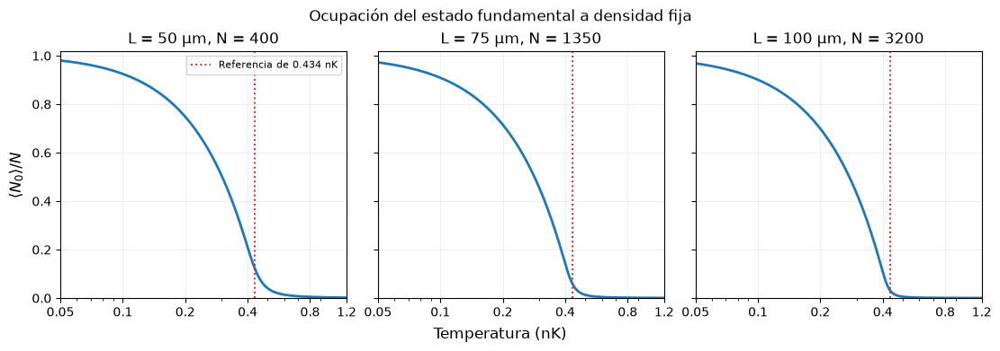

In [9]:
%matplotlib inline
# Pares (lado en µm, número de partículas) a densidad fija.
cajas = [(50, 400), (75, 1350), (100, 3200)]
temperaturas_nK = np.geomspace(0.05, 1.20, 141)
marcas_nK = [0.05, 0.1, 0.2, 0.4, 0.8, 1.2]

fig, ejes = plt.subplots(
    1, 3, figsize=(11, 3.8), sharex=True, sharey=True,
    layout="constrained",
)

for ax, (L_um, N_caja) in zip(ejes, cajas):
    L_caja = L_um * 1e-6
    fraccion_N0 = np.empty_like(temperaturas_nK)

    for j, T_nK in enumerate(temperaturas_nK):
        beta = 1 / (k_B * T_nK * 1e-9)

        z = [z_k(beta, k, m, L_caja) for k in range(1, N_caja + 1)]
        dz_dbeta = [
            d_z_k(beta, k, m, L_caja) for k in range(1, N_caja + 1)
        ]

        # La tercera salida de tu recurrencia es <N_0>.
        _, _, N0_media = canonic_recursion(z, dz_dbeta)
        fraccion_N0[j] = N0_media / N_caja

    ax.plot(temperaturas_nK, fraccion_N0, color="tab:blue", linewidth=2)
    ax.axvline(
        0.434, color="tab:red", linestyle=":", linewidth=1.4,
        label="Referencia de 0.434 nK",
    )
    ax.set(
        title=f"L = {L_um} µm, N = {N_caja}",
        xscale="log",
        xlim=(0.05, 1.20),
        ylim=(0, 1.02),
    )
    ax.set_xticks(marcas_nK, labels=[f"{valor:g}" for valor in marcas_nK])
    ax.grid(alpha=0.2)

ejes[0].legend(loc="upper right", fontsize=8)
fig.supxlabel("Temperatura (nK)")
fig.supylabel(r"$\langle N_0\rangle/N$")
fig.suptitle("Ocupación del estado fundamental a densidad fija")
plt.show()

Al aumentar $N$ y $L$ de forma que la densidad $N/L^3$ permanezca constante, la temperatura crítica $T_c$ predicha por la teoría en el límite termodinámico se mantiene fija. En las gráficas, a medida que aumenta el tamaño del sistema, la fracción condensada $\langle N_0 \rangle/N$ se acerca a cero y la curva se vuelve más horizontal por encima de $T_c$. Este comportamiento concuerda con la predicción de que la fracción condensada se anula por encima de $T_c$ en el límite termodinámico.

La línea vertical en $T = 0.434\,\mathrm{nK}$ sirve como referencia común en los tres paneles. Para determinar cómo varía con $N$ la temperatura de transición estimada, se debe aplicar el mismo criterio a cada curva.

# Direct-Sampling 

Sea $K$ la longitud del ciclo que contiene a una partícula de referencia.
En un sistema de $M$ bosones, la probabilidad de que dicho ciclo tenga
longitud $k$ es

$$
P(K=k)=\frac{z_k Z_{M-k}}{M Z_M},
\qquad k=1,\ldots,M.
$$

Lo que quiero es dado un numero N de particulas y una temperatura T que permutacion se presenta. Pero como estoy trabajando con bosones solo tengo que saber los ciclos que tiene esta permutacion en concreto (m1,m2,...). 

In [10]:
def reject_finite(pi):
    """
    Tengo los pesos individuales de K objetos. Uso un método de muestreo
    que selecciona un objeto con una probabilidad proporcional a su peso
    dado que desconosco la distribución de probabilidades.
 
    Sortea un índice k = 1, ..., K con probabilidad pi[k - 1] / sum(pi).
    Los pesos deben ser no negativos y al menos uno debe ser positivo.
    """
    K = len(pi)
    pi_max = max(pi)

    while True:
        # np.random.randint excluye el límite superior.
        k = np.random.randint(1, K + 1)
        r = np.random.uniform(0, pi_max)

        if r > pi[k - 1]:#Mi idea es dado que 
            continue  # Equivale a goto 1: vuelve a sortear k y r.

        return k

    
def direct_cycles(z, Z):
    """Sortea una estructura de ciclos. m[k] cuenta los ciclos de longitud k."""
    N = len(z)
    m = np.zeros(N + 1, dtype=int)
    M = N

    while M > 0:
        pesos = np.zeros(M, dtype=np.longdouble)

        # Para cada longitud k, el peso es z_k * Z_{M-k}.
        for k in range(1, M + 1):
            pesos[k - 1] = z[k - 1] * Z[M - k]

        # Reescalar todos los pesos por el mismo factor conserva el sorteo.
        pesos /= pesos.max()
        k = reject_finite(pesos)

        M -= k
        m[k] += 1

    return m

# Calculo de coordenadas 

Una vez que tengo la estructura de la permutación, necesito saber cuáles son las coordenadas de las partículas que participan en cada ciclo.

Defino $\beta = 1/(k_B T)$ como la duración de cada tramo en la variable de tiempo imaginario. Entonces, si el ciclo tiene longitud $k$, su duración total es $k\beta$. Para construir el camino, fijo un punto inicial $x_0$ y un punto final $x_k$. Como el ciclo es cerrado, $x_k$ representa la misma posición que $x_0$ dentro de la caja periódica.

Entre estos dos extremos construyo un **puente browniano**. Para generar cada posición intermedia $x_i$, parto de la posición inmediatamente anterior $x_{i-1}$ y tengo en cuenta el punto final $x_k$. Así obtengo las $k$ coordenadas que voy a dibujar, $x_0,x_1,\ldots,x_{k-1}$.

La idea es pensar que el tramo que comienza en la posición $x_i$ termina en $x_{i+1}$, que es la posición inicial de la siguiente partícula del ciclo. Así, cada partícula queda conectada con la siguiente y la última se conecta con la primera. Ese encadenamiento representa el intercambio en tiempo imaginario.

In [13]:
def levy_free_path(x0, xN, beta, N):
    """Genera un camino libre entre x0 y xN con N tramos."""
    x = np.zeros(N + 1)
    x[0] = x0
    x[N] = xN

    delta_tau = beta / N

    for k in range(1, N):
        # Intervalo que queda entre x[k] y el extremo final.
        delta_tau_restante = (N - k) * delta_tau

        # Media del siguiente punto, dados x[k - 1] y xN.
        x_media = (
            delta_tau_restante * x[k - 1] + delta_tau * xN
        ) / (delta_tau + delta_tau_restante)

        # Desviación estándar en metros si beta se ingresa en J^-1.
        sigma = np.sqrt(
            (HBAR**2 / m) / (1 / delta_tau + 1 / delta_tau_restante)
        )

        x[k] = x_media + np.random.normal(0, sigma)

    return x
# Estoy en fronteras periodicas por lo que tengo que tener esto encuenta 

def levy_periodic_path(x0, xN, beta, N, L):
    """Genera un camino de N tramos en una caja periódica de lado L."""
    varianza = HBAR**2 * beta / m

    # Entero w que sitúa la imagen de xN más cerca de x0.
    w_cercano = int(np.rint((x0 - xN) / L))
    distancia_min = xN + w_cercano * L - x0

    # Corte para la suma sobre las imágenes periódicas.
    w_max = int(np.ceil(np.sqrt(72 * varianza) / L)) + 1
    valores_w = np.arange(w_cercano - w_max, w_cercano + w_max + 1)
    pesos = np.zeros(len(valores_w))

    for j in range(len(valores_w)):
        w = valores_w[j]
        distancia = xN + w * L - x0

        # Pesos gaussianos relativos al de la imagen más cercana.
        pesos[j] = np.exp(
            -(distancia**2 - distancia_min**2) / (2 * varianza)
        )

    # tower_sample devuelve un índice que empieza en 1.
    indice = reject_finite(pesos)
    w = valores_w[indice - 1]

    camino = levy_free_path(x0, xN + w * L, beta, N)

    # Lleva todos los puntos al intervalo [0, L).
    return camino % L

# Grafica de ocupacion cerca de la temperatura critica 

In [12]:
temperaturas_video = np.linspace(0.70, 0.15, 45)  # nK
fps = 8


def perfil_momento(T_nK, N, m, L, sigma_q=0.07):
    """Calcula la densidad de momentos proyectada sobre qx y qy."""
    beta = 1 / (k_B * T_nK * 1e-9)
    a1 = beta * 2 * pi**2 * HBAR**2 / (m * L**2)

    k = np.arange(1, N + 1)
    n_max = int(np.ceil(np.sqrt(36 / a1)))
    n = np.arange(-n_max, n_max + 1)

    boltzmann = np.exp(-a1 * k[:, None] * n[None, :]**2)
    suma_qz = boltzmann.sum(axis=1)
    log_z = 3 * np.log(suma_qz)

    # Recursión canónica en logaritmos para calcular Z_{N-k}/Z_N.
    log_Z = np.zeros(N + 1)  # log(Z_0) = 0
    for M in range(1, N + 1):
        log_terminos = log_z[:M] + log_Z[M - 1::-1]
        log_Z[M] = np.logaddexp.reduce(log_terminos) - np.log(M)

    cocientes = np.exp(log_Z[N - k] - log_Z[N])
    N0_media = cocientes.sum()

    # Ocupación de cada par (qx, qy), sumada sobre los modos qz.
    ocupacion_xy = boltzmann.T @ (
        (cocientes * suma_qz)[:, None] * boltzmann
    )

    # Suavizado de los modos discretos para visualizar la superficie.
    q_modos = (2 * pi / L) * n * 1e-6  # µm⁻¹
    q = np.linspace(-1.5, 1.5, 121)
    diferencia = q[:, None] - q_modos[None, :]
    gauss = np.exp(-0.5 * (diferencia / sigma_q)**2)
    gauss /= np.sqrt(2 * pi) * sigma_q

    densidad = gauss @ ocupacion_xy @ gauss.T
    Qx, Qy = np.meshgrid(q, q, indexing="ij")

    return Qx, Qy, densidad, N0_media


def animar_momentos(temperaturas, N, m, L, fps=8):
    perfiles = [perfil_momento(T, N, m, L) for T in temperaturas]
    altura_maxima = max(densidad.max() for _, _, densidad, _ in perfiles)

    fig, ax = plt.subplots(
        figsize=(7, 5.5),
        subplot_kw={"projection": "3d"},
        layout="constrained",
    )

    Qx, Qy, _, _ = perfiles[0]
    ax.set(
        xlabel=r"$q_x$ ($\mu\mathrm{m}^{-1}$)",
        ylabel=r"$q_y$ ($\mu\mathrm{m}^{-1}$)",
        zlabel=r"$d^2N/(dq_x\,dq_y)$",
        xlim=(Qx.min(), Qx.max()),
        ylim=(Qy.min(), Qy.max()),
        zlim=(0, 1.05 * altura_maxima),
    )
    ax.view_init(elev=27, azim=-55)
    titulo = ax.set_title("")
    superficie = None

    def actualizar(i):
        nonlocal superficie

        if superficie is not None:
            superficie.remove()

        Qx, Qy, densidad, N0_media = perfiles[i]
        superficie = ax.plot_surface(
            Qx, Qy, densidad,
            cmap="turbo_r",
            vmin=0,
            vmax=altura_maxima,
            rstride=3,
            cstride=3,
            edgecolor="0.3",
            linewidth=0.15,
        )

        titulo.set_text(
            f"T = {temperaturas[i]:.3f} nK\n"
            f"Fracción en el estado fundamental = {N0_media / N:.1%}"
        )

    animacion = FuncAnimation(
        fig,
        actualizar,
        frames=len(perfiles),
        interval=1000 / fps,
        repeat=False,
    )
    plt.close(fig)
    return animacion


from IPython.display import HTML, display

N_valores = [400]
temperaturas_video = np.linspace(3, 0.15, 100)  # nK
fps = 8

for N_bosones in N_valores:
    display(HTML(f"<h3>{N_bosones} bosones</h3>"))

    animacion = animar_momentos(
        temperaturas_video,
        N_bosones,
        m,
        L,
        fps=fps,
    )

    display(HTML(animacion.to_jshtml(default_mode="once")))